# Optimizers in PyTorch: How They Work and How to Choose

An optimizer decides **how to turn a gradient into a weight update**. Same model, same data, same loss: different optimizers can train at very different speeds, or not train at all.

**What you will learn**

1. The update rule behind SGD, momentum, Nesterov, Adagrad, RMSprop, Adam and AdamW
2. How each one behaves on a hard loss surface (you will watch the paths)
3. Why comparing optimizers at default learning rates is misleading, and how to compare them fairly
4. How learning-rate schedules and warmup change the picture
5. A practical decision guide for choosing an optimizer

The structure follows the usual PyTorch loop: an `nn.Module`, a `DataLoader`, `train_one_epoch` / `evaluate`, and a `fit` function that records history.

## 0. Setup

In [1]:
import copy
import math
import random

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 0


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)   # tiny networks run faster single-threaded on CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

torch 2.15.0+cu132 | device: cpu


## 1. The update rules at a glance

Let `g_t` be the gradient at step `t`, `lr` the learning rate, and `θ` the weights.

| Optimizer | Idea | Update (simplified) | Extra state per weight |
|---|---|---|---|
| **SGD** | step downhill | `θ ← θ − lr·g` | none |
| **SGD + momentum** | keep a running velocity so consistent directions speed up and zig-zags cancel | `v ← μ·v + g`; `θ ← θ − lr·v` | 1 (velocity) |
| **Nesterov** | momentum, but take the gradient at the *looked-ahead* point | like momentum, with a look-ahead correction | 1 |
| **Adagrad** | per-weight step size that shrinks as squared gradients accumulate | `s ← s + g²`; `θ ← θ − lr·g/(√s+ε)` | 1 |
| **RMSprop** | like Adagrad but with a *decaying* average, so it does not stall | `s ← ρ·s + (1−ρ)·g²`; `θ ← θ − lr·g/(√s+ε)` | 1 |
| **Adam** | momentum on the gradient *plus* RMSprop-style scaling, with bias correction | `m ← β₁m+(1−β₁)g`; `s ← β₂s+(1−β₂)g²`; `θ ← θ − lr·m̂/(√ŝ+ε)` | 2 |
| **AdamW** | Adam with weight decay applied *directly to the weights*, separate from the gradient | Adam step, then `θ ← θ − lr·wd·θ` | 2 |

Two ideas explain almost everything in the table:

- **Momentum** smooths direction. It helps in narrow valleys where plain SGD bounces side to side.
- **Adaptive scaling** (dividing by a running gradient magnitude) gives each weight its own step size. It helps when different weights have very different gradient scales.

To make the rules concrete, here is SGD with momentum written by hand next to PyTorch's version. They should produce identical results.

In [2]:
def sgd_momentum_by_hand(theta, grad_fn, lr, mu, steps):
    v = torch.zeros_like(theta)
    for _ in range(steps):
        g = grad_fn(theta)
        v = mu * v + g            # velocity accumulates gradients
        theta = theta - lr * v    # step along the velocity
    return theta


def quad_grad(t):                 # gradient of f(t) = 0.5 * t^T A t, A = diag(1, 10)
    return torch.stack([1.0 * t[0], 10.0 * t[1]])


theta0 = torch.tensor([2.0, 1.0])
by_hand = sgd_momentum_by_hand(theta0.clone(), quad_grad, lr=0.05, mu=0.9, steps=50)

p = theta0.clone().requires_grad_(True)
opt = torch.optim.SGD([p], lr=0.05, momentum=0.9)
for _ in range(50):
    opt.zero_grad()
    loss = 0.5 * (p[0] ** 2 + 10.0 * p[1] ** 2)
    loss.backward()
    opt.step()

print("by hand :", by_hand.numpy())
print("PyTorch :", p.detach().numpy())
print("match   :", torch.allclose(by_hand, p.detach(), atol=1e-5))

by hand : [0.01184978 0.07060864]
PyTorch : [0.01184978 0.07060864]
match   : True


## 2. Watching optimizers move on a hard surface

We use an **ill-conditioned bowl**: `f(x, y) = 0.5·(x² + 30·y²)`. It is a long narrow valley, 30 times steeper in `y` than in `x`. The minimum is at the origin. All optimizers start from the same point.

A single global learning rate has a problem here: it must be small enough not to blow up in the steep `y` direction, which makes progress in the shallow `x` direction slow.

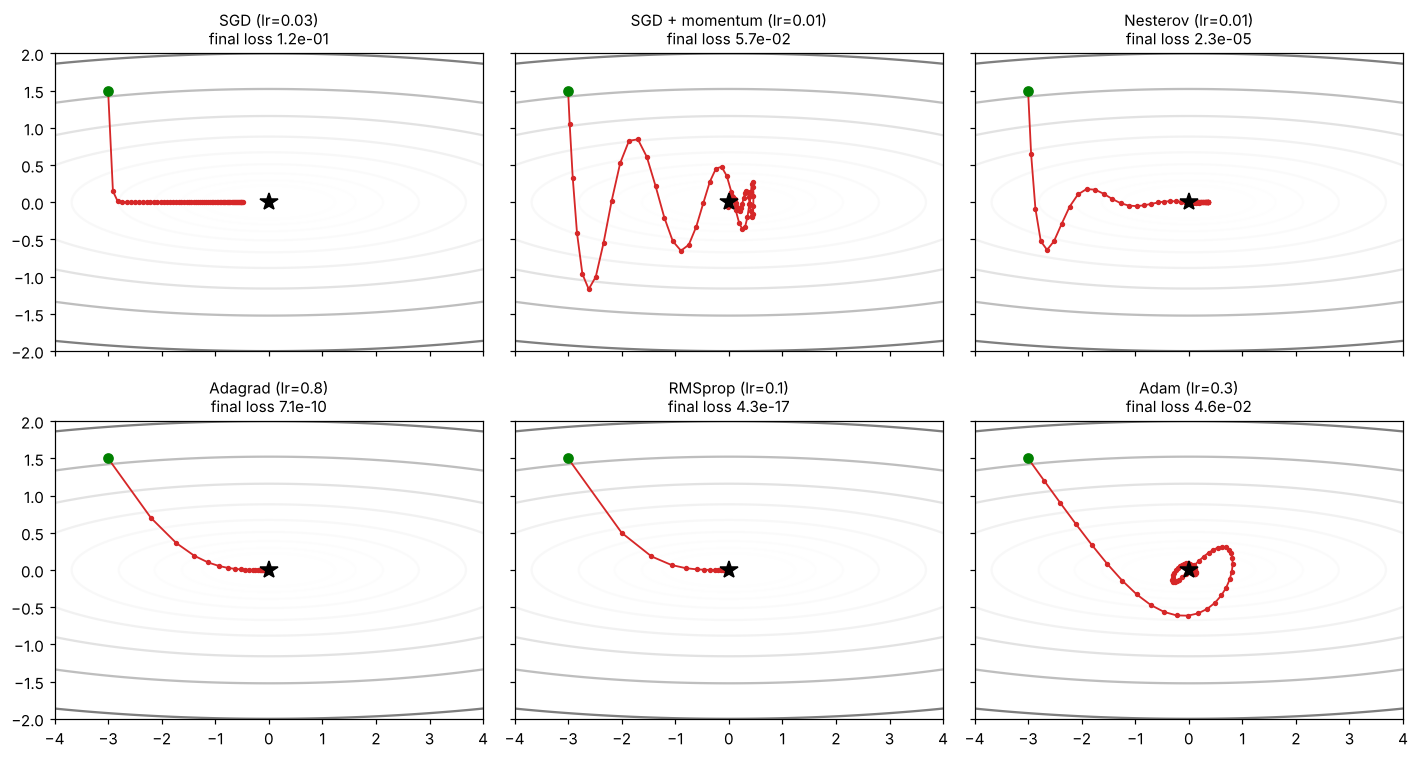

In [3]:
def f(p):
    return 0.5 * (p[0] ** 2 + 30.0 * p[1] ** 2)


def run_path(make_opt, start=(-3.0, 1.5), steps=60):
    p = torch.tensor(start, requires_grad=True)
    opt = make_opt([p])
    path, losses = [p.detach().numpy().copy()], [f(p).item()]
    for _ in range(steps):
        opt.zero_grad()
        loss = f(p)
        loss.backward()
        opt.step()
        path.append(p.detach().numpy().copy())
        losses.append(f(p).item())
    return np.array(path), np.array(losses)


toy = {
    "SGD (lr=0.03)":             lambda ps: torch.optim.SGD(ps, lr=0.03),
    "SGD + momentum (lr=0.01)":  lambda ps: torch.optim.SGD(ps, lr=0.01, momentum=0.9),
    "Nesterov (lr=0.01)":        lambda ps: torch.optim.SGD(ps, lr=0.01, momentum=0.9, nesterov=True),
    "Adagrad (lr=0.8)":          lambda ps: torch.optim.Adagrad(ps, lr=0.8),
    "RMSprop (lr=0.1)":          lambda ps: torch.optim.RMSprop(ps, lr=0.1),
    "Adam (lr=0.3)":             lambda ps: torch.optim.Adam(ps, lr=0.3),
}
paths = {name: run_path(mk) for name, mk in toy.items()}

xs, ys = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-2, 2, 200))
zs = 0.5 * (xs ** 2 + 30.0 * ys ** 2)

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
for ax, (name, (path, losses)) in zip(axes.ravel(), paths.items()):
    ax.contour(xs, ys, zs, levels=np.geomspace(0.05, 60, 14), cmap="Greys", alpha=0.5)
    ax.plot(path[:, 0], path[:, 1], "-o", ms=2.5, lw=1.2, color="tab:red")
    ax.plot(*path[0], "go"); ax.plot(0, 0, "k*", ms=12)
    ax.set_title(f"{name}\nfinal loss {losses[-1]:.1e}", fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()

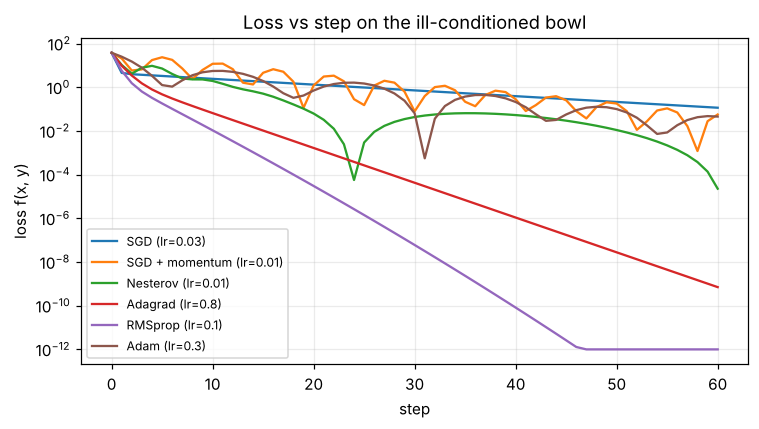

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, (_, losses) in paths.items():
    ax.plot(np.maximum(losses, 1e-12), label=name)
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("loss f(x, y)")
ax.set_title("Loss vs step on the ill-conditioned bowl"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

What the paths show:

- **Plain SGD** is limited by the steep direction: it drops into the valley floor in a couple of steps, then creeps along `x` because the learning rate that is safe in `y` is tiny for `x`.
- **Momentum** builds speed along `x` but overshoots and swings across the valley, so it is still oscillating at the end of 60 steps. **Nesterov** uses the look-ahead gradient to damp that swinging, and here it settles far better (compare the final losses in the titles). That is one setting, not a general ranking.
- **Adagrad and RMSprop** rescale each coordinate by its gradient magnitude, which largely removes the conditioning problem: both head almost straight to the minimum.
- **Adam** also rescales per coordinate, so it starts out heading directly toward the minimum, but its momentum term makes it overshoot and spiral around the minimum at this fairly large learning rate. A smaller `lr` or a decay schedule would tighten that.

**Caution.** This is a 2-D, noise-free, convex toy. It shows *mechanisms*, not which optimizer wins on real networks. The learning rates above were picked by hand for this picture (and Adam is not at its best here), which is exactly why the next sections tune each one properly.

### Learning rate matters more than the optimizer's name

The same SGD, with three different learning rates:

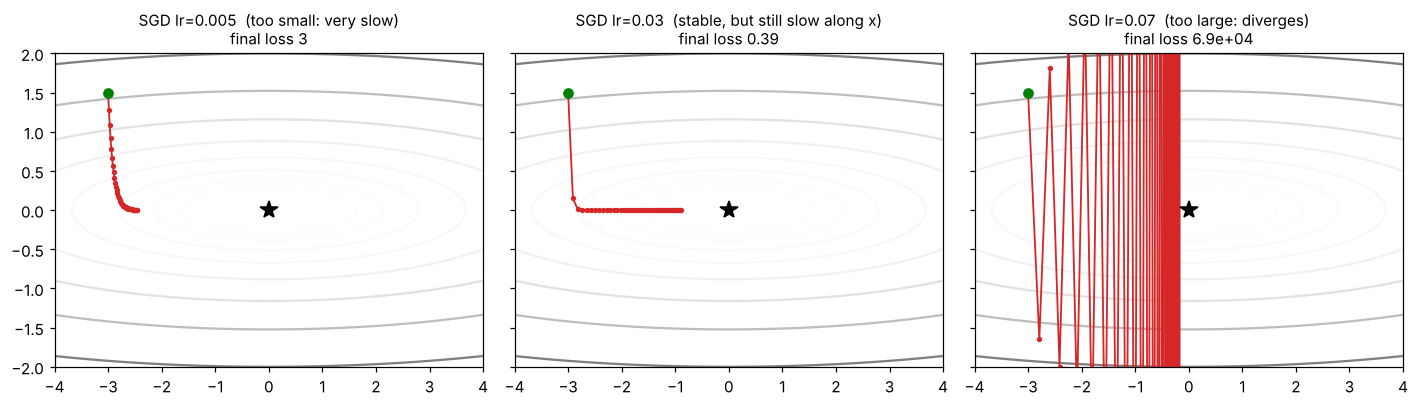

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, lr in zip(axes, [0.005, 0.03, 0.07]):
    path, losses = run_path(lambda ps, lr=lr: torch.optim.SGD(ps, lr=lr), steps=40)
    ax.contour(xs, ys, zs, levels=np.geomspace(0.05, 60, 14), cmap="Greys", alpha=0.5)
    ax.plot(path[:, 0], path[:, 1], "-o", ms=2.5, lw=1.2, color="tab:red")
    ax.plot(*path[0], "go"); ax.plot(0, 0, "k*", ms=12)
    state = ("too small: very slow" if lr < 0.01
             else ("stable, but still slow along x" if lr < 0.06 else "too large: diverges"))
    ax.set_title(f"SGD lr={lr}  ({state})\nfinal loss {losses[-1]:.2g}", fontsize=10)
    ax.set_xlim(-4, 4); ax.set_ylim(-2, 2); ax.grid(False)
plt.tight_layout(); plt.show()

For plain SGD the stability limit is `lr < 2 / (largest curvature)`. Here the largest curvature is 30, so the limit is about `0.067`. At `lr=0.07` the steep direction flips sign and grows every step. This is the same thing that happens as `NaN` losses when you set the learning rate too high in a real network.

## 3. A real comparison: training a network

We switch to a real (small) classification task: scikit-learn's **handwritten digits** (8×8 images, 10 classes). It is small enough to run on a CPU in seconds yet has real non-convex training dynamics.

Splits: 1000 train, 400 validation, the rest test. Validation is for choosing learning rates; the test set is for one final honest number.

train=1000  val=400  test=397


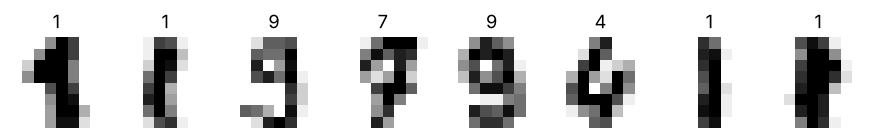

In [6]:
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)          # scale pixels to [0, 1]
yd = digits.target.astype(np.int64)

X_tr, X_rest, y_tr, y_rest = train_test_split(Xd, yd, train_size=1000, stratify=yd, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, train_size=400, stratify=y_rest, random_state=SEED)
print(f"train={len(X_tr)}  val={len(X_va)}  test={len(X_te)}")

fig, axes = plt.subplots(1, 8, figsize=(10, 1.6))
for ax, img, lab in zip(axes, X_tr[:8], y_tr[:8]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r"); ax.set_title(int(lab)); ax.axis("off")
plt.show()

In [7]:
class MLP(nn.Module):
    def __init__(self, in_dim=64, hidden=128, out_dim=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


def make_loader(X, y, batch_size=64, shuffle=False):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


loss_fn = nn.CrossEntropyLoss()
val_loader = make_loader(X_va, y_va, batch_size=512)
test_loader = make_loader(X_te, y_te, batch_size=512)


def train_one_epoch(model, loader, optimizer, scheduler=None):
    model.train()
    running, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()                # per-step schedule
        running += loss.item() * len(xb); n += len(xb)
    return running / n


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total += loss_fn(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total / n, correct / n

In [8]:
def fit(make_opt, epochs=30, seed=SEED, make_sched=None, batch_size=64):
    """Train a fresh MLP with the optimizer built by `make_opt(params)`.
    `make_sched(optimizer, steps_per_epoch, epochs)` optionally returns a per-step LR scheduler."""
    set_seed(seed)
    model = MLP().to(device)
    optimizer = make_opt(model.parameters())
    loader = make_loader(X_tr, y_tr, batch_size=batch_size, shuffle=True)
    scheduler = make_sched(optimizer, len(loader), epochs) if make_sched else None

    h = {"train_loss": [], "val_loss": [], "val_acc": [], "lr": []}
    for _ in range(epochs):
        h["lr"].append(optimizer.param_groups[0]["lr"])
        tl = train_one_epoch(model, loader, optimizer, scheduler)
        vl, va = evaluate(model, val_loader)
        if not math.isfinite(tl):           # diverged: stop and mark the rest as failed
            tl = vl = float("inf"); va = 0.1
        h["train_loss"].append(tl); h["val_loss"].append(vl); h["val_acc"].append(va)
    h["model"] = model
    return h

### 3a. The tempting (but flawed) comparison: "default" learning rates

First do what most people do: run each optimizer with its common textbook learning rate.

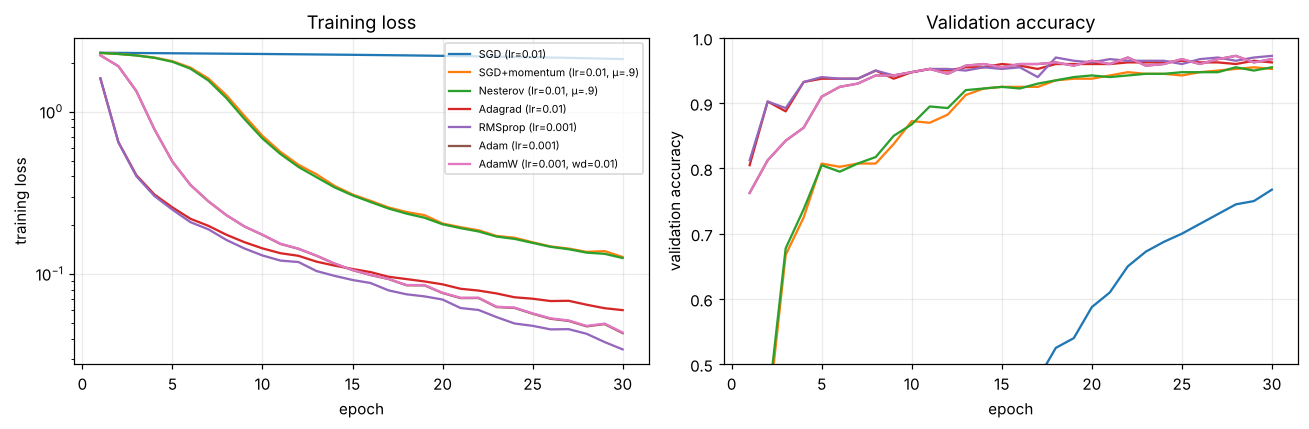

optimizer                        final train loss  final val acc
SGD (lr=0.01)                              2.1086          0.767
SGD+momentum (lr=0.01, μ=.9)               0.1272          0.953
Nesterov (lr=0.01, μ=.9)                   0.1253          0.955
Adagrad (lr=0.01)                          0.0599          0.963
RMSprop (lr=0.001)                         0.0343          0.973
Adam (lr=0.001)                            0.0432          0.968
AdamW (lr=0.001, wd=0.01)                  0.0436          0.968


In [9]:
EPOCHS = 30
defaults = {
    "SGD (lr=0.01)":                lambda ps: torch.optim.SGD(ps, lr=0.01),
    "SGD+momentum (lr=0.01, μ=.9)": lambda ps: torch.optim.SGD(ps, lr=0.01, momentum=0.9),
    "Nesterov (lr=0.01, μ=.9)":     lambda ps: torch.optim.SGD(ps, lr=0.01, momentum=0.9, nesterov=True),
    "Adagrad (lr=0.01)":            lambda ps: torch.optim.Adagrad(ps, lr=0.01),
    "RMSprop (lr=0.001)":           lambda ps: torch.optim.RMSprop(ps, lr=1e-3),
    "Adam (lr=0.001)":              lambda ps: torch.optim.Adam(ps, lr=1e-3),
    "AdamW (lr=0.001, wd=0.01)":    lambda ps: torch.optim.AdamW(ps, lr=1e-3, weight_decay=1e-2),
}
hist_default = {name: fit(mk, epochs=EPOCHS) for name, mk in defaults.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in hist_default.items():
    axes[0].plot(range(1, EPOCHS + 1), h["train_loss"], label=name)
    axes[1].plot(range(1, EPOCHS + 1), h["val_acc"], label=name)
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("Training loss")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy"); axes[1].set_title("Validation accuracy")
axes[1].set_ylim(0.5, 1.0); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'optimizer':<32} {'final train loss':>16} {'final val acc':>14}")
for name, h in hist_default.items():
    print(f"{name:<32} {h['train_loss'][-1]:>16.4f} {h['val_acc'][-1]:>14.3f}")

This looks like a ranking of optimizers, but it is really a ranking of **how well each default learning rate happens to suit this model**. Plain SGD at `0.01` is simply under-powered here; that does not mean SGD is a bad optimizer. A fair comparison needs each optimizer to get its own tuned learning rate.

### 3b. A fair comparison: tune the learning rate for each optimizer

For each optimizer we sweep the learning rate on a log grid, training from scratch each time (2 seeds), and score by **final validation loss**. Runs that diverge to `NaN` count as failures.

In [10]:
lrs = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
sweep_seeds = [0, 1]
factories = {
    "SGD":          lambda lr: (lambda ps: torch.optim.SGD(ps, lr=lr)),
    "SGD+momentum": lambda lr: (lambda ps: torch.optim.SGD(ps, lr=lr, momentum=0.9)),
    "Nesterov":     lambda lr: (lambda ps: torch.optim.SGD(ps, lr=lr, momentum=0.9, nesterov=True)),
    "Adagrad":      lambda lr: (lambda ps: torch.optim.Adagrad(ps, lr=lr)),
    "RMSprop":      lambda lr: (lambda ps: torch.optim.RMSprop(ps, lr=lr)),
    "Adam":         lambda lr: (lambda ps: torch.optim.Adam(ps, lr=lr)),
    "AdamW":        lambda lr: (lambda ps: torch.optim.AdamW(ps, lr=lr, weight_decay=1e-2)),
}

sweep = {name: [] for name in factories}      # mean final val loss per lr
for name, fac in factories.items():
    for lr in lrs:
        vals = []
        for s in sweep_seeds:
            h = fit(fac(lr), epochs=25, seed=s)
            vals.append(h["val_loss"][-1])
        sweep[name].append(np.mean(vals))

best = {}
for name, vals in sweep.items():
    arr = np.array(vals, dtype=float)
    arr[~np.isfinite(arr)] = np.inf
    i = int(np.argmin(arr))
    best[name] = (lrs[i], arr[i])

print(f"{'optimizer':<14} {'best lr':>8} {'val loss at best lr':>20}")
for name, (lr, vl) in best.items():
    print(f"{name:<14} {lr:>8g} {vl:>20.4f}")

optimizer       best lr  val loss at best lr
SGD                 0.3               0.1248
SGD+momentum        0.1               0.1202
Nesterov           0.03               0.1225
Adagrad            0.03               0.0945
RMSprop            0.01               0.0901
Adam               0.01               0.1066
AdamW              0.01               0.1106


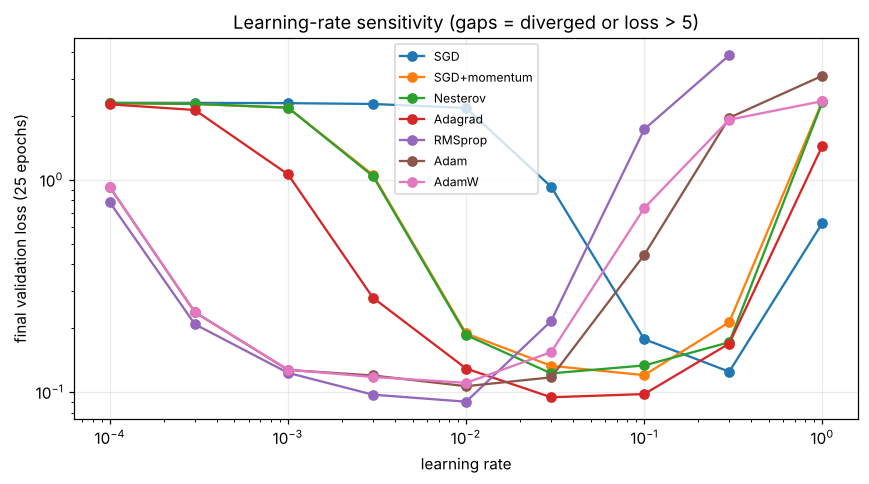

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, vals in sweep.items():
    arr = np.array(vals, dtype=float)
    arr = np.where(np.isfinite(arr) & (arr < 5), arr, np.nan)       # clip diverged runs for display
    ax.plot(lrs, arr, marker="o", label=name)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("learning rate"); ax.set_ylabel("final validation loss (25 epochs)")
ax.set_title("Learning-rate sensitivity (gaps = diverged or loss > 5)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Read the **width and position of each valley**:

- Every optimizer has a *sweet spot*, and the sweet spots sit in very different places. Plain SGD and momentum want rates 10 to 30 times larger than Adam/RMSprop/AdamW here.
- The **width of the valley** tells you how forgiving an optimizer is: how far off you can be and still do well. In this experiment the valleys are of broadly similar width (roughly one to one-and-a-half orders of magnitude). RMSprop is steepest on the high side and blows up quickly past its best rate.
- So the practical difference here is mostly **where** the valley sits, not how wide it is. Adam, RMSprop and AdamW work well from about `1e-3` to `1e-2`, which is why `1e-3` is such a common starting point for them (a safe, slightly slow default; with only 25 epochs, `1e-2` won). For SGD-family methods the best rate depends more on the scale of your gradients, so a sweep is more important.
- The sweep uses only 2 seeds and a short 25-epoch budget. Small differences between the best points (for example `0.09` vs `0.12`) are within noise.

Now re-run each optimizer at its **own best learning rate** and compare on the held-out test set.

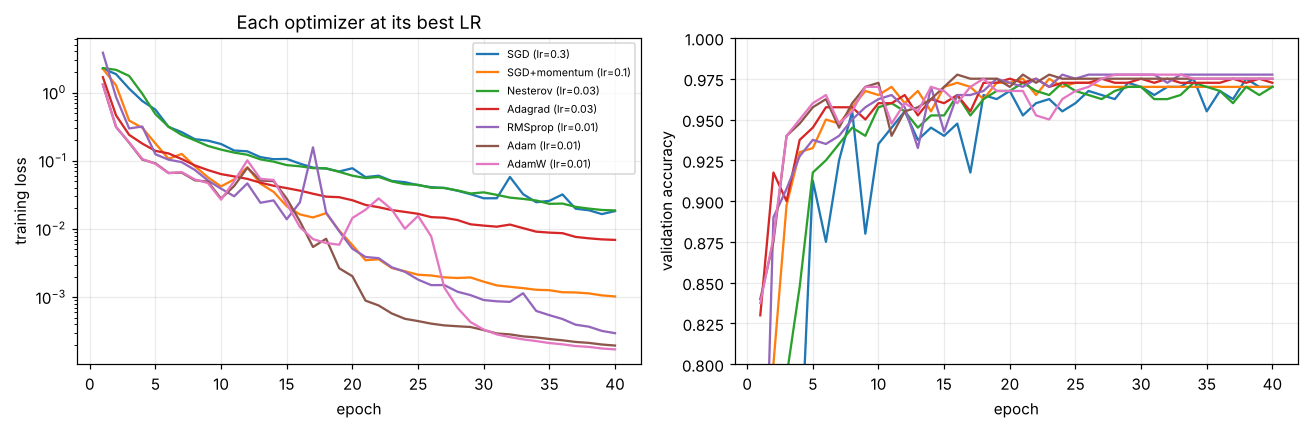

optimizer          lr  final train loss  val acc  test acc
SGD               0.3            0.0183    0.970     0.980
SGD+momentum      0.1            0.0010    0.970     0.982
Nesterov         0.03            0.0187    0.970     0.970
Adagrad          0.03            0.0069    0.973     0.977
RMSprop          0.01            0.0003    0.978     0.975
Adam             0.01            0.0002    0.975     0.982
AdamW            0.01            0.0002    0.975     0.982


In [12]:
final = {}
for name, (lr, _) in best.items():
    h = fit(factories[name](lr), epochs=40, seed=0)
    te_loss, te_acc = evaluate(h["model"], test_loader)
    final[name] = dict(h=h, lr=lr, test_acc=te_acc, test_loss=te_loss)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in final.items():
    axes[0].plot(range(1, 41), r["h"]["train_loss"], label=f"{name} (lr={r['lr']:g})")
    axes[1].plot(range(1, 41), r["h"]["val_acc"], label=name)
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("Each optimizer at its best LR")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy"); axes[1].set_ylim(0.8, 1.0)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'optimizer':<14} {'lr':>6} {'final train loss':>17} {'val acc':>8} {'test acc':>9}")
for name, r in final.items():
    h = r["h"]
    print(f"{name:<14} {r['lr']:>6g} {h['train_loss'][-1]:>17.4f} {h['val_acc'][-1]:>8.3f} {r['test_acc']:>9.3f}")

Once each optimizer has a tuned learning rate, the **gaps between them shrink a lot** compared with the default-LR comparison. On a small, easy problem like this, most reasonably tuned optimizers end up in the same neighborhood of accuracy; what differs is mostly *speed* (how many epochs to get there) and *how hard they were to tune*.

Be careful reading small accuracy differences: the test set has about 400 points, so one accuracy number has a standard error of around 1 percentage point, and we used a single seed for this final run. Differences of that size are noise.

## 4. Learning-rate schedules and warmup

A fixed learning rate is a compromise: big enough to make fast progress early, but then too big to settle precisely into a minimum. **Schedules** change the learning rate during training. We compare, for SGD with momentum and for Adam, a constant rate, a **cosine decay**, and **linear warmup followed by cosine decay**.

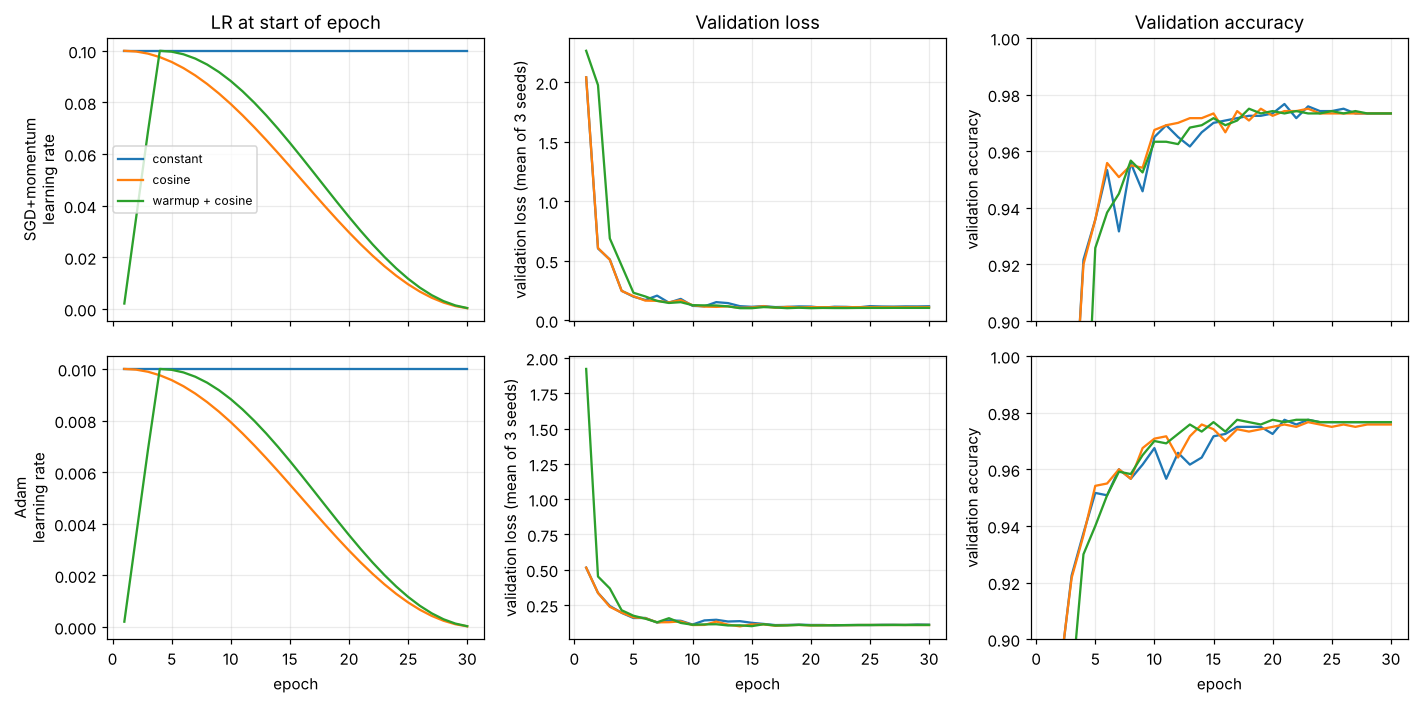

optimizer      schedule           final val loss  final val acc
SGD+momentum   constant                   0.1181          0.973
SGD+momentum   cosine                     0.1110          0.973
SGD+momentum   warmup + cosine            0.1044          0.973
Adam           constant                   0.1102          0.977
Adam           cosine                     0.1079          0.976
Adam           warmup + cosine            0.1080          0.977


In [13]:
def const_sched(opt, steps_per_epoch, epochs):
    return torch.optim.lr_scheduler.LambdaLR(opt, lambda step: 1.0)


def cosine_sched(opt, steps_per_epoch, epochs):
    total = steps_per_epoch * epochs
    return torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))


def warmup_cosine_sched(opt, steps_per_epoch, epochs, warmup_epochs=3):
    total, warm = steps_per_epoch * epochs, steps_per_epoch * warmup_epochs
    def lam(s):
        if s < warm:
            return (s + 1) / warm                                 # linear warmup from ~0
        prog = (s - warm) / max(1, total - warm)
        return 0.5 * (1 + math.cos(math.pi * prog))               # cosine decay to 0
    return torch.optim.lr_scheduler.LambdaLR(opt, lam)


scheds = {"constant": const_sched, "cosine": cosine_sched, "warmup + cosine": warmup_cosine_sched}
bases = {
    "SGD+momentum": lambda ps: torch.optim.SGD(ps, lr=best["SGD+momentum"][0], momentum=0.9),
    "Adam":         lambda ps: torch.optim.Adam(ps, lr=best["Adam"][0]),
}

EPOCHS_S = 30
sched_res = {}
for oname, mk in bases.items():
    for sname, ms in scheds.items():
        runs = [fit(mk, epochs=EPOCHS_S, seed=s, make_sched=ms) for s in [0, 1, 2]]
        sched_res[(oname, sname)] = runs

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for row, oname in enumerate(bases):
    for sname in scheds:
        runs = sched_res[(oname, sname)]
        vl = np.mean([r["val_loss"] for r in runs], axis=0)
        axes[row, 0].plot(range(1, EPOCHS_S + 1), runs[0]["lr"], label=sname)
        axes[row, 1].plot(range(1, EPOCHS_S + 1), vl, label=sname)
        axes[row, 2].plot(range(1, EPOCHS_S + 1), np.mean([r["val_acc"] for r in runs], axis=0), label=sname)
    axes[row, 0].set_ylabel(f"{oname}\nlearning rate"); axes[row, 1].set_ylabel("validation loss (mean of 3 seeds)")
    axes[row, 2].set_ylabel("validation accuracy"); axes[row, 2].set_ylim(0.9, 1.0)
for ax in axes[1]:
    ax.set_xlabel("epoch")
axes[0, 0].set_title("LR at start of epoch"); axes[0, 1].set_title("Validation loss"); axes[0, 2].set_title("Validation accuracy")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'optimizer':<14} {'schedule':<17} {'final val loss':>15} {'final val acc':>14}")
for (oname, sname), runs in sched_res.items():
    print(f"{oname:<14} {sname:<17} {np.mean([r['val_loss'][-1] for r in runs]):>15.4f} "
          f"{np.mean([r['val_acc'][-1] for r in runs]):>14.3f}")

What schedules do, in general:

- **Decay** (cosine, step, linear) lets the optimizer take big steps early and fine-grained steps at the end, which generally lowers the final loss versus a constant rate. In this run it did so modestly for SGD with momentum (final validation loss fell from about 0.118 to 0.111 with cosine). For Adam the three schedules finished within about 0.003 of each other, which is not a meaningful difference.
- **Warmup** starts with a tiny rate and ramps up. It matters most for Adam-style optimizers on large or transformer-style models, where the second-moment estimates are unreliable in the first steps. On this tiny MLP there is no clear benefit: SGD with warmup finished slightly lower, but with 3 seeds that gap is too small to trust, and Adam shows nothing.

Validation accuracy is essentially the same across all six runs. Judge these curves against the seed-to-seed noise: with 3 seeds and a small dataset, small differences in the table are not reliable.

## 5. How to choose an optimizer

There is no universally best optimizer. These are good defaults and the reasons behind them.

### A practical decision guide

| Situation | Reasonable starting point | Why |
|---|---|---|
| **No strong prior, want something that works** | **Adam / AdamW**, `lr ≈ 1e-3` | forgiving, little tuning, handles different gradient scales |
| **Transformers / large language models** | **AdamW** + warmup + cosine/linear decay | the standard recipe; decoupled weight decay behaves better than Adam's L2 |
| **CNNs on image classification, chasing best final accuracy** | **SGD + momentum (0.9)**, Nesterov optional, with a decay schedule | often competitive or better at the end of a long, well-tuned run, but needs LR tuning |
| **Sparse features (embeddings, bag-of-words)** | Adagrad or Adam | rarely-seen features keep larger effective steps |
| **Recurrent nets, reinforcement learning** | RMSprop or Adam | non-stationary, noisy gradients |
| **Memory is tight (huge models)** | SGD (+momentum) | Adam keeps 2 extra tensors per weight, SGD 0-1 |
| **Fine-tuning a pretrained model** | AdamW with a *small* LR (e.g. `1e-5` to `5e-5`) | do not wreck pretrained weights |

Treat these as defaults, not rules. They reflect common practice; the right choice on your problem comes from validation results.

### A tuning protocol that works

1. **Pick a default** from the table (usually AdamW at `1e-3`).
2. **Sweep the learning rate on a log grid** (like section 3b). It is the single most important hyperparameter, whatever the optimizer.
3. **Look at the loss curve first.** `NaN` or exploding loss: lr too high. Barely moving: lr too low. Noisy and plateaued early: add decay.
4. **Add a schedule** (cosine decay; warmup if using Adam on a big model).
5. **Then** tune secondary knobs: momentum, `β₂`, weight decay, batch size.
6. **Compare optimizers only after tuning each one's learning rate**, using validation data, over several seeds. Use the test set once at the end.

### Notes on claims you will hear

- *"Adam converges faster."* Often true in early training and when you cannot afford much tuning: at the default-style rates in section 3a, Adam and RMSprop were ahead of plain SGD and momentum. But once every optimizer had a tuned learning rate (3b), the final results were close. Faster out of the box is not the same as a better final model.
- *"SGD generalizes better than Adam."* A commonly reported pattern on some vision tasks, but results depend on tuning, weight decay and schedule, and it is not a law. This notebook does **not** test it.
- *"AdamW is just Adam."* With weight decay they differ: Adam adds an L2 term to the gradient, which then gets rescaled by the adaptive denominator; AdamW shrinks the weights directly. That is why AdamW is the usual choice when you want weight decay with an adaptive optimizer.

## 6. Exercises

1. **Momentum value.** In section 3b, change momentum from `0.9` to `0.5` and `0.99`. How does the best learning rate shift? (Higher momentum effectively multiplies the step size.)
2. **Adam's β₂.** Try `betas=(0.9, 0.99)` and `(0.9, 0.9)`. When does Adam become unstable?
3. **Batch size.** Rerun the comparison with `batch_size` of 8 and 256. Which optimizers care most? How should the best LR change with batch size?
4. **Adam vs AdamW.** Use a larger network or smaller training set so overfitting appears, then compare `Adam(weight_decay=...)` with `AdamW(weight_decay=...)` over a decay sweep.
5. **Schedules.** Add `OneCycleLR` and `StepLR` to section 4. Which is best for SGD? For Adam?
6. **Epsilon.** Set Adam's `eps` to `1e-3` and to `1e-1`. What happens, and why does a large `eps` make Adam behave like SGD with momentum?
7. **New problem.** Replace the digits MLP with a small CNN or a different dataset. Do the best learning rates and the ranking change?